In [ ]:
# Import libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from scipy.cluster.hierarchy import dendrogram, linkage

from sklearn.base import clone
from sklearn.model_selection import (
    train_test_split, GridSearchCV, StratifiedKFold, KFold,
    cross_validate, cross_val_predict, validation_curve
)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier, RandomForestRegressor
)
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    roc_curve, classification_report, confusion_matrix, ConfusionMatrixDisplay,
    mean_absolute_error, mean_squared_error, r2_score,
    silhouette_score, adjusted_rand_score
)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")

# Standard seed used throughout the notebook for reproducibility
SEED = 42

In [ ]:
# Load dataset
file_path = r'C:\Users\Lenovo\OneDrive\Dokumente\New learning\Ironhack\Final project\clean_employee_data.csv'
employee_df = pd.read_csv(file_path)
employee_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1470 non-null   int64
 1   Attrition                 1470 non-null   int64
 2   BusinessTravel            1470 non-null   int64
 3   DailyRate                 1470 non-null   int64
 4   Department                1470 non-null   int64
 5   DistanceFromHome          1470 non-null   int64
 6   Education                 1470 non-null   int64
 7   EducationField            1470 non-null   int64
 8   EnvironmentSatisfaction   1470 non-null   int64
 9   Gender                    1470 non-null   int64
 10  HourlyRate                1470 non-null   int64
 11  JobInvolvement            1470 non-null   int64
 12  JobLevel                  1470 non-null   int64
 13  JobRole                   1470 non-null   int64
 14  JobSatisfaction           1470 non-null 

In [ ]:
#Describtion
employee_df.describe()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,0.161224,1.607483,802.485714,1.260544,9.192517,2.912925,2.247619,2.721769,0.600000,...,3.153741,2.712245,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,0.367863,0.665455,403.509100,0.527792,8.106864,1.024165,1.331369,1.093082,0.490065,...,0.360824,1.081209,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,0.000000,0.000000,102.000000,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,...,3.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,0.000000,1.000000,465.000000,1.000000,2.000000,2.000000,1.000000,2.000000,0.000000,...,3.000000,2.000000,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,0.000000,2.000000,802.000000,1.000000,7.000000,3.000000,2.000000,3.000000,1.000000,...,3.000000,3.000000,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,0.000000,2.000000,1157.000000,2.000000,14.000000,4.000000,3.000000,4.000000,1.000000,...,3.000000,4.000000,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1.000000,2.000000,1499.000000,2.000000,29.000000,5.000000,5.000000,4.000000,1.000000,...,4.000000,4.000000,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [ ]:
# Attrition
employee_df["Attrition"] = employee_df["Attrition"].map({
    "Yes": 1,
    "No": 0
}).fillna(employee_df["Attrition"]).astype(int)

employee_df["Attrition"].value_counts()

Attrition
0    1233
1     237
Name: count, dtype: int64

In [ ]:
#Percentage
attrition_counts = employee_df["Attrition"].value_counts()
print(attrition_counts)
attrition_percentage = employee_df["Attrition"].value_counts(normalize=True) * 100

print("\nPercentage:")
print(attrition_percentage)

Attrition
0    1233
1     237
Name: count, dtype: int64

Percentage:
Attrition
0    83.877551
1    16.122449
Name: proportion, dtype: float64


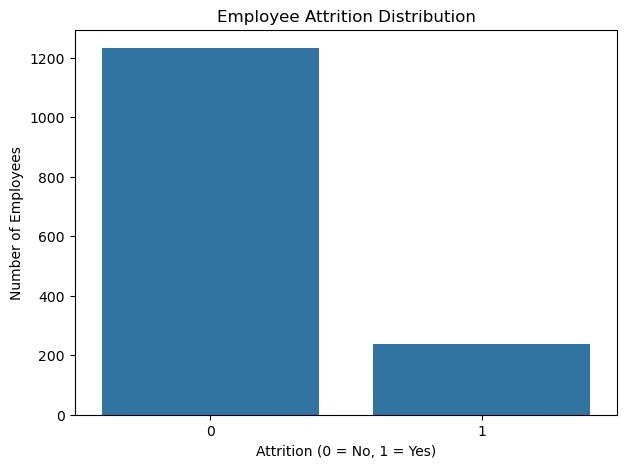

In [ ]:
#Number of Employees
plt.figure(figsize=(7, 5))

sns.countplot(
    data= employee_df,
    x="Attrition"
)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition (0 = No, 1 = Yes)")
plt.ylabel("Number of Employees")

plt.show()

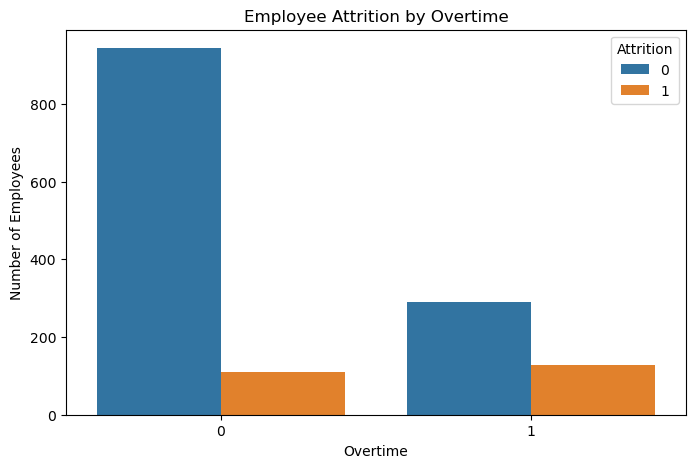

In [ ]:
#Overtime
plt.figure(figsize=(8, 5))

sns.countplot(
    data=employee_df,
    x="OverTime",
    hue="Attrition"
)

plt.title("Employee Attrition by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Number of Employees")

plt.show()

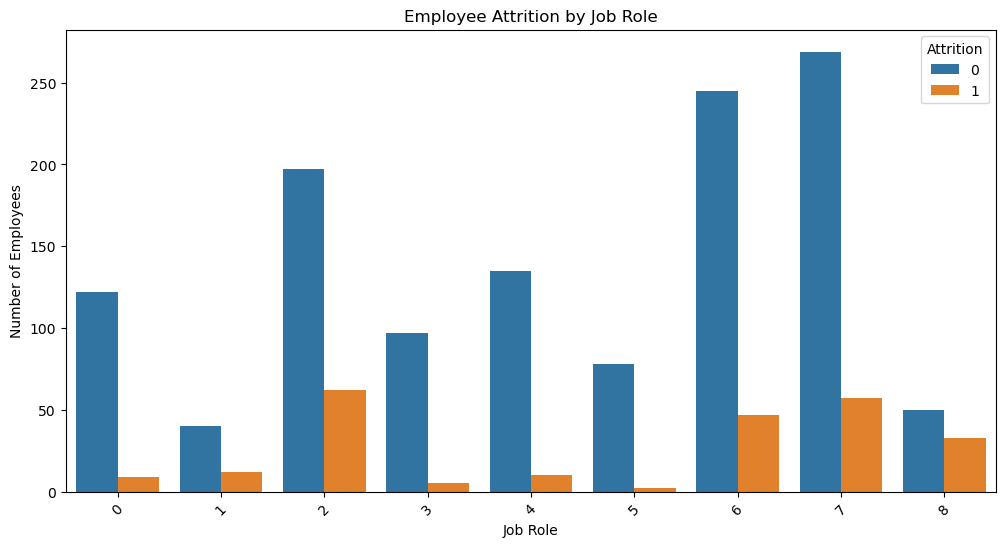

In [ ]:
#Job Role
plt.figure(figsize=(12, 6))

sns.countplot(
    data=employee_df,
    x="JobRole",
    hue="Attrition"
)

plt.title("Employee Attrition by Job Role")
plt.xticks(rotation=45)
plt.xlabel("Job Role")
plt.ylabel("Number of Employees")

plt.show()

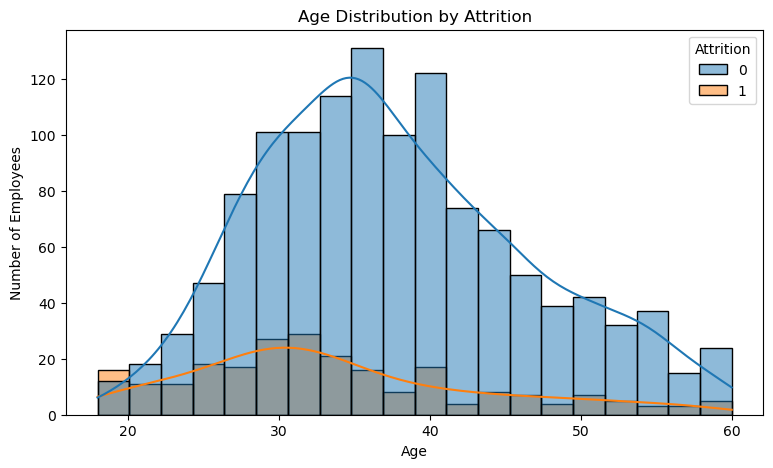

In [ ]:
#Age Distribution
plt.figure(figsize=(9, 5))

sns.histplot(
    data=employee_df,
    x="Age",
    hue="Attrition",
    kde=True,
    bins=20
)

plt.title("Age Distribution by Attrition")
plt.xlabel("Age")
plt.ylabel("Number of Employees")

plt.show()

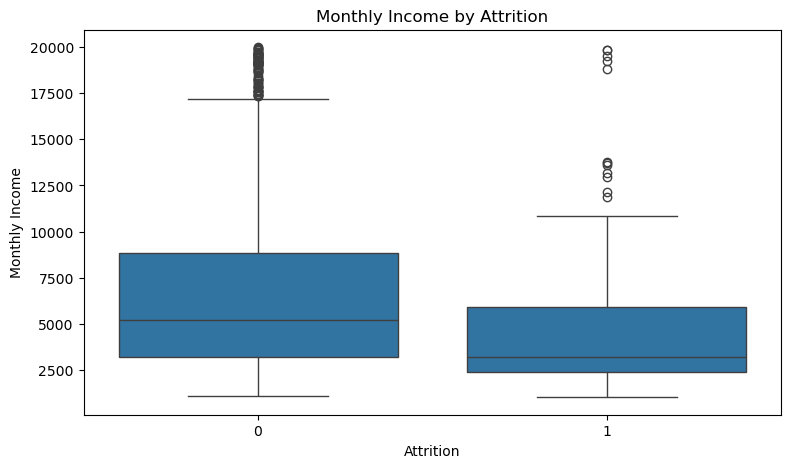

In [ ]:
#Monthly Income
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=employee_df,
    x="Attrition",
    y="MonthlyIncome"
)
plt.title("Monthly Income by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")

plt.show()

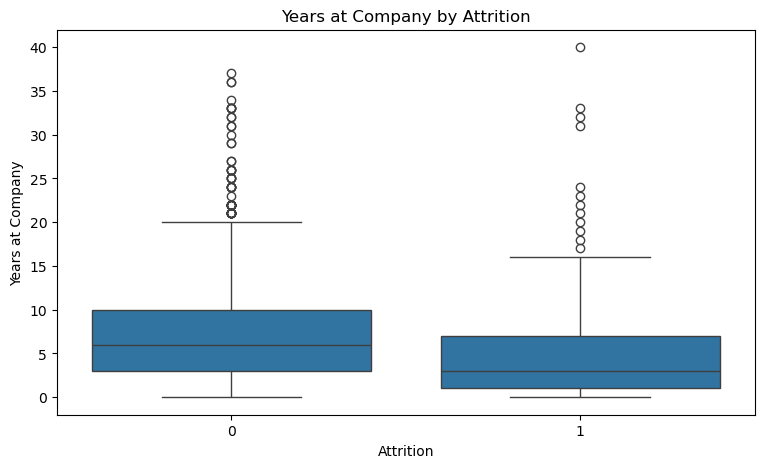

In [ ]:
#Year at company
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=employee_df,
    x="Attrition",
    y="YearsAtCompany"
)
plt.title("Years at Company by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Years at Company")

plt.show()

In [ ]:
X = employee_df.drop("Attrition", axis=1)
y = employee_df["Attrition"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (1470, 30)
Target: (1470,)


In [ ]:
# Categorical features
categorical_features = [
    "BusinessTravel", "Department", "EducationField", "JobRole", "MaritalStatus"
]
numeric_features = [c for c in X.columns if c not in categorical_features]

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

Numerical features: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical features: ['BusinessTravel', 'Department', 'EducationField', 'JobRole', 'MaritalStatus']


In [ ]:
#Training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1176
Testing samples: 294


In [ ]:
#Feature preprocessing
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

try:
    categorical_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    categorical_encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", categorical_encoder)
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

In [ ]:
#Baseline Logistic Regression
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000
            )
        )
    ]
)

logistic_pipeline.fit(X_train, y_train)

y_pred = logistic_pipeline.predict(X_test)
y_probability = logistic_pipeline.predict_proba(X_test)[:, 1]

In [ ]:
#Evaluate baseline model
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probability)

print("Baseline Logistic Regression")
print("--------------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC : {roc_auc:.4f}")

Baseline Logistic Regression
--------------------------------
Accuracy : 0.8605
Precision: 0.6154
Recall : 0.3404
F1 Score : 0.4384
ROC-AUC : 0.8122


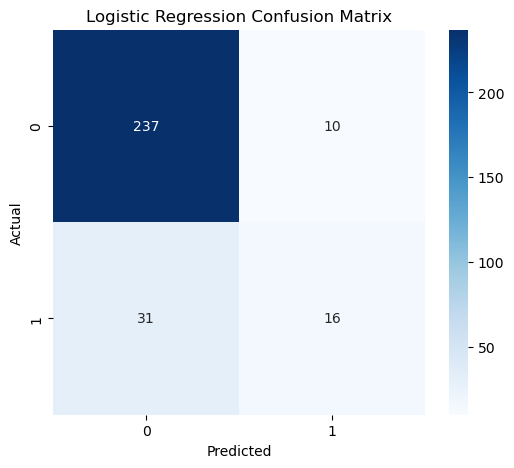

In [ ]:
#Confusion matrix
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
#Compare multiple classification models
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "KNN": KNeighborsClassifier(),

    "SVM": SVC(
        probability=True,
        random_state=42
    ),

    "Naive Bayes": GaussianNB(),

    "Random Forest": RandomForestClassifier(
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

In [ ]:
#Train and evaluate all models
results = []

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", model)
        ]
    )

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "Precision": precision_score(
            y_test,
            predictions
        ),
        "Recall": recall_score(
            y_test,
            predictions
        ),
        "F1": f1_score(
            y_test,
            predictions
        ),
        "ROC_AUC": roc_auc_score(
            y_test,
            probabilities
        )
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1",
        ascending=False
    )

)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.860544,0.615385,0.340426,0.438356,0.812215
4,Naive Bayes,0.642857,0.258333,0.659574,0.371257,0.687398
6,Gradient Boosting,0.857143,0.666667,0.212766,0.322581,0.804290
1,Decision Tree,0.772109,0.300000,0.319149,0.309278,0.588724
3,SVM,0.860544,0.750000,0.191489,0.305085,0.814627
2,KNN,0.840136,0.500000,0.148936,0.229508,0.639073
5,Random Forest,0.843537,0.571429,0.085106,0.148148,0.772633


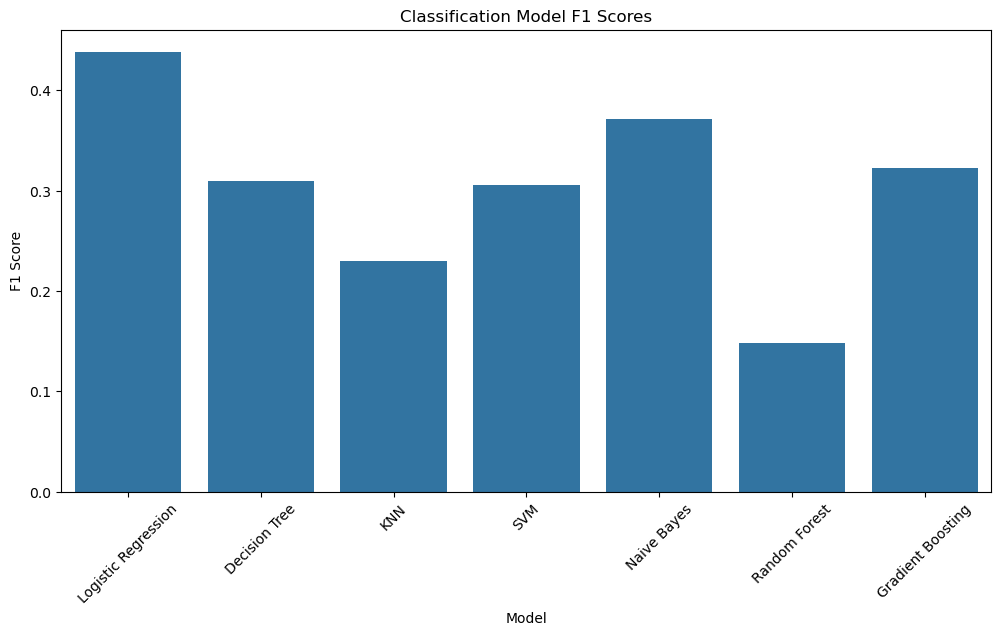

In [ ]:
#Visualize model performance
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1"
)

plt.title("Classification Model F1 Scores")
plt.xticks(rotation=45)
plt.ylabel("F1 Score")

plt.show()

In [ ]:
#Handle class imbalance with SMOTE
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE
except ImportError:
    raise ImportError("Install imbalanced-learn with: pip install imbalanced-learn")

smote_pipeline = ImbPipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("classifier", LogisticRegression(max_iter=2000))
    ]
)

smote_pipeline.fit(X_train, y_train)

smote_predictions = smote_pipeline.predict(X_test)
smote_probabilities = smote_pipeline.predict_proba(X_test)[:, 1]


In [ ]:
#Execution
print("Logistic Regression + SMOTE")

print(
    "Accuracy:",
    accuracy_score(
        y_test,
        smote_predictions
    )
)

print(
    "Precision:",
    precision_score(
        y_test,
        smote_predictions
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        smote_predictions
    )
)

print(
    "F1:",
    f1_score(
        y_test,
        smote_predictions
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        smote_probabilities
    )
)

Logistic Regression + SMOTE
Accuracy: 0.7755102040816326
Precision: 0.379746835443038
Recall: 0.6382978723404256
F1: 0.47619047619047616
ROC-AUC: 0.7992075114135585


In [ ]:
#Classification models
def make_models(balanced=False):
    """Fresh model instances. balanced=True keeps only models with class_weight."""
    cw = "balanced" if balanced else None
    models = {
        "Logistic Regression": LogisticRegression(max_iter=2000, class_weight=cw),
        "Decision Tree": DecisionTreeClassifier(random_state=SEED, class_weight=cw),
        "SVM": SVC(probability=True, random_state=SEED, class_weight=cw),
        "Random Forest": RandomForestClassifier(random_state=SEED, class_weight=cw),
    }
    if not balanced:   # these have no class_weight parameter
        models["KNN"] = KNeighborsClassifier()
        models["Naive Bayes"] = GaussianNB()
        models["Gradient Boosting"] = GradientBoostingClassifier(random_state=SEED)
    return models


def evaluate(pipe, X_tr, y_tr, X_te, y_te):
    """Fit on train, score on test."""
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    proba = pipe.predict_proba(X_te)[:, 1]
    return {
        "Accuracy": accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred, zero_division=0),
        "Recall": recall_score(y_te, pred),
        "F1": f1_score(y_te, pred),
        "ROC_AUC": roc_auc_score(y_te, proba),
    }


def plain_pipe(model):
    return Pipeline([("preprocessor", preprocessor), ("classifier", model)])


def smote_pipe(model):
    return ImbPipeline([
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=SEED)),
        ("classifier", model),
    ])

In [ ]:
#Class-imbalance handling
rows = []
for name, model in make_models().items():
    rows.append({"Strategy": "Baseline", "Model": name,
                 **evaluate(plain_pipe(model), X_train, y_train, X_test, y_test)})
for name, model in make_models(balanced=True).items():
    rows.append({"Strategy": "Class weights", "Model": name,
                 **evaluate(plain_pipe(model), X_train, y_train, X_test, y_test)})
for name, model in make_models().items():
    rows.append({"Strategy": "SMOTE", "Model": name,
                 **evaluate(smote_pipe(model), X_train, y_train, X_test, y_test)})

imbalance_df = pd.DataFrame(rows)

display(imbalance_df.pivot(index="Model", columns="Strategy", values="Recall")
        .round(3).style.set_caption("Recall by imbalance strategy"))
display(imbalance_df.pivot(index="Model", columns="Strategy", values="F1")
        .round(3).style.set_caption("F1 by imbalance strategy"))
display(imbalance_df.pivot(index="Model", columns="Strategy", values="ROC_AUC")
        .round(3).style.set_caption("ROC-AUC by imbalance strategy"))

Strategy,Baseline,Class weights,SMOTE
Model,,,
Decision Tree,0.319000,0.277000,0.362000
Gradient Boosting,0.213000,nan,0.319000
KNN,0.149000,nan,0.617000
Logistic Regression,0.340000,0.638000,0.638000
Naive Bayes,0.660000,nan,0.617000
Random Forest,0.085000,0.064000,0.213000
SVM,0.191000,0.617000,0.468000


Strategy,Baseline,Class weights,SMOTE
Model,,,
Decision Tree,0.309000,0.274000,0.351000
Gradient Boosting,0.323000,nan,0.411000
KNN,0.230000,nan,0.354000
Logistic Regression,0.438000,0.451000,0.476000
Naive Bayes,0.371000,nan,0.296000
Random Forest,0.148000,0.113000,0.308000
SVM,0.305000,0.547000,0.473000


Strategy,Baseline,Class weights,SMOTE
Model,,,
Decision Tree,0.589000,0.567000,0.614000
Gradient Boosting,0.804000,nan,0.793000
KNN,0.639000,nan,0.687000
Logistic Regression,0.812000,0.803000,0.799000
Naive Bayes,0.687000,nan,0.648000
Random Forest,0.773000,0.749000,0.773000
SVM,0.815000,0.810000,0.749000


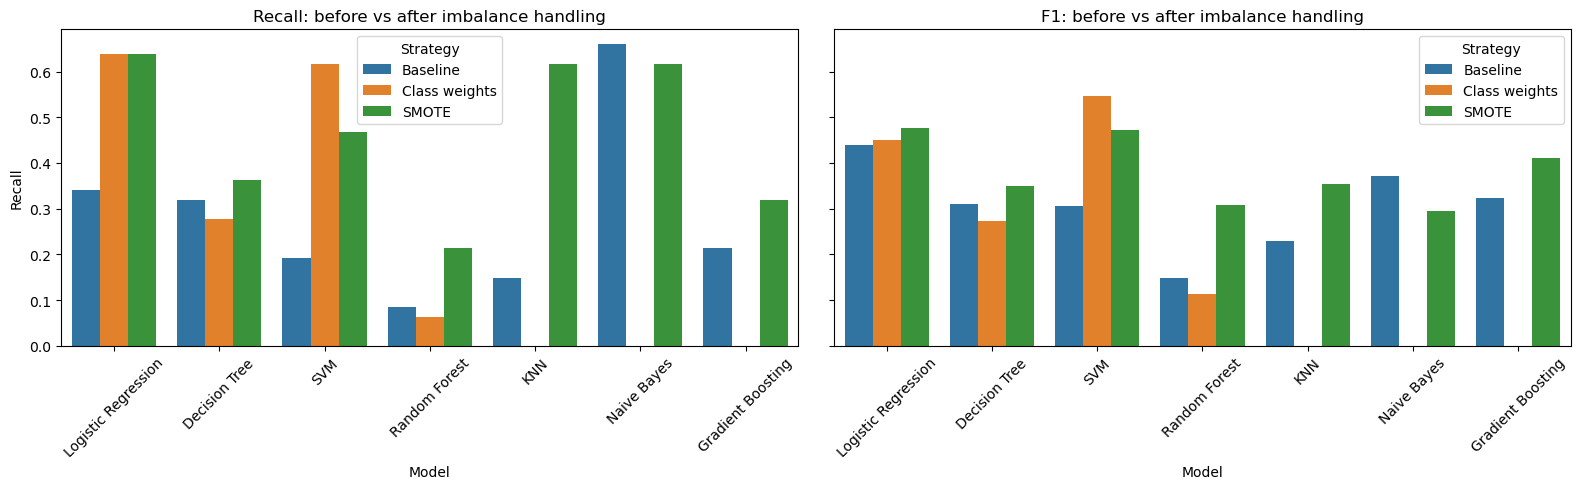

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, metric in zip(axes, ["Recall", "F1"]):
    sns.barplot(data=imbalance_df, x="Model", y=metric, hue="Strategy", ax=ax)
    ax.set_title(f"{metric}: before vs after imbalance handling")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
#Stratified Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_rows = []
for strategy, builder in [("Baseline", plain_pipe), ("SMOTE", smote_pipe)]:
    for name, model in make_models().items():
        res = cross_validate(builder(model), X_train, y_train, cv=cv,
                             scoring=scoring, n_jobs=-1)
        row = {"Strategy": strategy, "Model": name}
        for m in scoring:
            row[f"{m}_mean"] = res[f"test_{m}"].mean()
            row[f"{m}_std"] = res[f"test_{m}"].std()
        cv_rows.append(row)

cv_df = pd.DataFrame(cv_rows)
display(cv_df.sort_values("f1_mean", ascending=False).round(3))

,Strategy,Model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Baseline,Logistic Regression,0.889,0.018,0.775,0.073,0.437,0.089,0.557,0.092,0.839,0.029
7,SMOTE,Logistic Regression,0.783,0.025,0.408,0.034,0.716,0.054,0.517,0.020,0.829,0.026
13,SMOTE,Gradient Boosting,0.874,0.017,0.705,0.103,0.379,0.095,0.488,0.097,0.813,0.040
9,SMOTE,SVM,0.849,0.016,0.544,0.064,0.442,0.093,0.483,0.070,0.791,0.029
6,Baseline,Gradient Boosting,0.872,0.010,0.742,0.069,0.332,0.064,0.453,0.063,0.809,0.017
5,Baseline,Naive Bayes,0.639,0.079,0.283,0.037,0.758,0.084,0.408,0.032,0.755,0.029
10,SMOTE,Random Forest,0.867,0.011,0.745,0.095,0.274,0.077,0.395,0.085,0.811,0.033
11,SMOTE,KNN,0.633,0.029,0.265,0.021,0.711,0.055,0.385,0.028,0.708,0.030
12,SMOTE,Naive Bayes,0.581,0.064,0.252,0.036,0.779,0.043,0.379,0.039,0.742,0.034
8,SMOTE,Decision Tree,0.785,0.023,0.356,0.045,0.405,0.091,0.375,0.058,0.632,0.039


In [ ]:
#Hyperparameter tuning
search_space = {
    "Random Forest": (
        RandomForestClassifier(random_state=SEED),
        {"classifier__n_estimators": [200, 400],
         "classifier__max_depth": [None, 5, 10],
         "classifier__min_samples_leaf": [1, 2, 4]},
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=SEED),
        {"classifier__max_depth": [3, 5, 7, 10, None],
         "classifier__min_samples_leaf": [1, 5, 10, 20],
         "classifier__criterion": ["gini", "entropy"]},
    ),
    "SVM": (
        SVC(probability=True, random_state=SEED),
        {"classifier__C": [0.1, 1, 10],
         "classifier__kernel": ["rbf", "linear"],
         "classifier__gamma": ["scale", 0.01, 0.001]},
    ),
    "KNN": (
        KNeighborsClassifier(),
        {"classifier__n_neighbors": [3, 5, 7, 11, 15, 21],
         "classifier__weights": ["uniform", "distance"],
         "classifier__p": [1, 2]},
    ),
}

tuned_models, tuned_rows = {}, []
for name, (model, grid) in search_space.items():
    gs = GridSearchCV(smote_pipe(model), param_grid=grid, cv=cv, scoring="f1",
                      n_jobs=-1, return_train_score=True)
    gs.fit(X_train, y_train)
    tuned_models[name] = gs.best_estimator_

    best = gs.best_index_
    train_f1 = gs.cv_results_["mean_train_score"][best]
    cv_f1 = gs.best_score_
    test_metrics = evaluate(clone(gs.best_estimator_), X_train, y_train, X_test, y_test)

    tuned_rows.append({
        "Model": name,
        "Best_Params": {k.replace("classifier__", ""): v for k, v in gs.best_params_.items()},
        "CV_F1": cv_f1,
        "Train_F1": train_f1,
        "Train_minus_CV_gap": train_f1 - cv_f1,     # large gap = high variance / overfitting
        **{f"Test_{k}": v for k, v in test_metrics.items()},
    })
    print(f"{name:14s} best CV F1 = {cv_f1:.3f} | params = {gs.best_params_}")

tuned_df = pd.DataFrame(tuned_rows).sort_values("CV_F1", ascending=False)
display(tuned_df.drop(columns="Best_Params").round(3))

Random Forest  best CV F1 = 0.508 | params = {'classifier__max_depth': 5, 'classifier__min_samples_leaf': 1, 'classifier__n_estimators': 400}
Decision Tree  best CV F1 = 0.409 | params = {'classifier__criterion': 'gini', 'classifier__max_depth': 5, 'classifier__min_samples_leaf': 10}
SVM            best CV F1 = 0.535 | params = {'classifier__C': 1, 'classifier__gamma': 0.01, 'classifier__kernel': 'rbf'}
KNN            best CV F1 = 0.449 | params = {'classifier__n_neighbors': 21, 'classifier__p': 1, 'classifier__weights': 'distance'}


,Model,CV_F1,Train_F1,Train_minus_CV_gap,Test_Accuracy,Test_Precision,Test_Recall,Test_F1,Test_ROC_AUC
2,SVM,0.535,0.655,0.120,0.820,0.455,0.638,0.531,0.792
0,Random Forest,0.508,0.711,0.203,0.813,0.409,0.383,0.396,0.778
3,KNN,0.449,1.000,0.551,0.752,0.324,0.511,0.397,0.732
1,Decision Tree,0.409,0.556,0.148,0.765,0.280,0.298,0.289,0.608


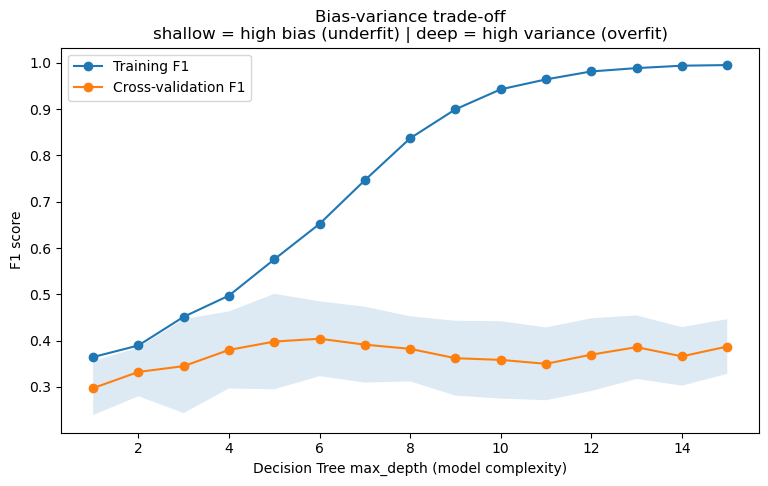

In [ ]:
# Bias-variance illustration: Decision Tree depth vs train / CV F1
depths = np.arange(1, 16)
train_sc, val_sc = validation_curve(
    smote_pipe(DecisionTreeClassifier(random_state=SEED)),
    X_train, y_train,
    param_name="classifier__max_depth", param_range=depths,
    cv=cv, scoring="f1", n_jobs=-1
)

plt.figure(figsize=(9, 5))
plt.plot(depths, train_sc.mean(axis=1), "o-", label="Training F1")
plt.plot(depths, val_sc.mean(axis=1), "o-", label="Cross-validation F1")
plt.fill_between(depths, val_sc.mean(1) - val_sc.std(1), val_sc.mean(1) + val_sc.std(1), alpha=0.15)
plt.xlabel("Decision Tree max_depth (model complexity)")
plt.ylabel("F1 score")
plt.title("Bias-variance trade-off\nshallow = high bias (underfit) | deep = high variance (overfit)")
plt.legend()
plt.show()

Selected model: SVM
              precision    recall  f1-score   support

        Stay       0.93      0.85      0.89       247
       Leave       0.45      0.64      0.53        47

    accuracy                           0.82       294
   macro avg       0.69      0.75      0.71       294
weighted avg       0.85      0.82      0.83       294

ROC-AUC: 0.7915


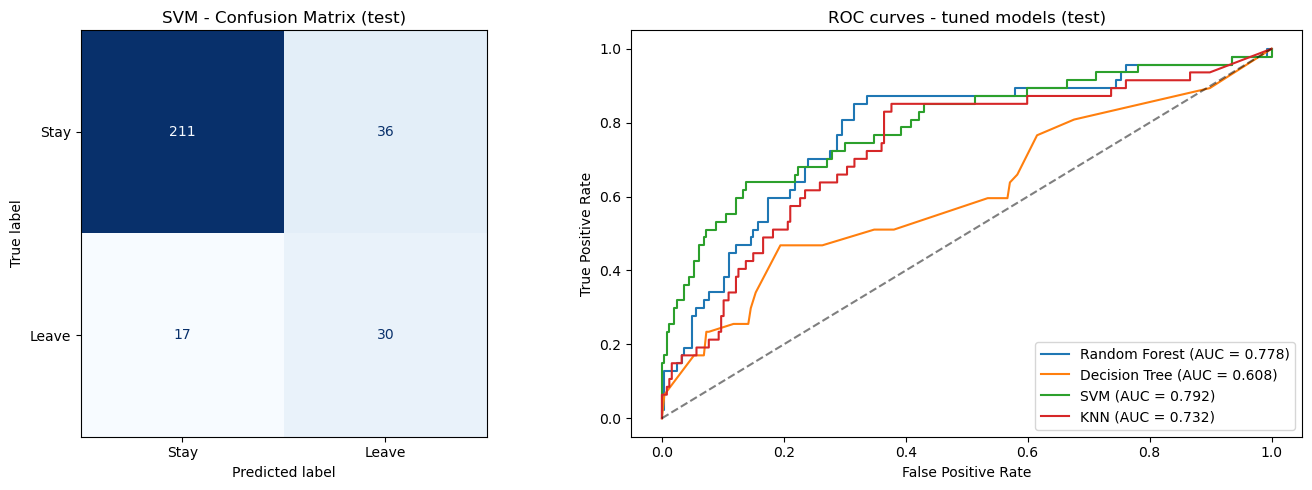

In [ ]:
#Final model selection and evaluation
best_name = tuned_df.iloc[0]["Model"]
final_model = tuned_models[best_name]
print("Selected model:", best_name)

final_pred = final_model.predict(X_test)
final_proba = final_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, final_pred, target_names=["Stay", "Leave"]))
print("ROC-AUC:", round(roc_auc_score(y_test, final_proba), 4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay(confusion_matrix(y_test, final_pred),
                       display_labels=["Stay", "Leave"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"{best_name} - Confusion Matrix (test)")

for name, mdl in tuned_models.items():
    fpr, tpr, _ = roc_curve(y_test, mdl.predict_proba(X_test)[:, 1])
    auc = roc_auc_score(y_test, mdl.predict_proba(X_test)[:, 1])
    axes[1].plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC curves - tuned models (test)")
axes[1].legend()
plt.tight_layout()
plt.show()

In [ ]:
#Regression
X_reg = employee_df.drop(columns=["MonthlyIncome", "Attrition"])
y_reg = employee_df["MonthlyIncome"]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=SEED
)

reg_categorical = [c for c in categorical_features if c in X_reg.columns]
reg_numeric = [c for c in X_reg.columns if c not in reg_categorical]

reg_preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), reg_numeric),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]),
     reg_categorical),
])

reg_models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree Regression": DecisionTreeRegressor(max_depth=6, min_samples_leaf=10, random_state=SEED),
    "Random Forest Regression": RandomForestRegressor(n_estimators=300, min_samples_leaf=2,
                                                      random_state=SEED, n_jobs=-1),
}

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
reg_rows, reg_fitted = [], {}
for name, model in reg_models.items():
    pipe = Pipeline([("preprocessor", reg_preprocessor), ("regressor", model)])
    pipe.fit(Xr_train, yr_train)
    pred = pipe.predict(Xr_test)
    cv_scores = cross_validate(clone(pipe), Xr_train, yr_train, cv=kf, scoring="r2")["test_score"]
    reg_fitted[name] = pipe
    reg_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(yr_test, pred),
        "RMSE": np.sqrt(mean_squared_error(yr_test, pred)),
        "R2": r2_score(yr_test, pred),
        "CV_R2_mean": cv_scores.mean(),
    })

regression_df = pd.DataFrame(reg_rows).sort_values("R2", ascending=False)
display(regression_df.round(3))

,Model,MAE,RMSE,R2,CV_R2_mean
2,Random Forest Regression,820.692,1098.644,0.945,0.951
0,Linear Regression,891.739,1167.426,0.938,0.939
1,Decision Tree Regression,891.699,1224.629,0.931,0.948


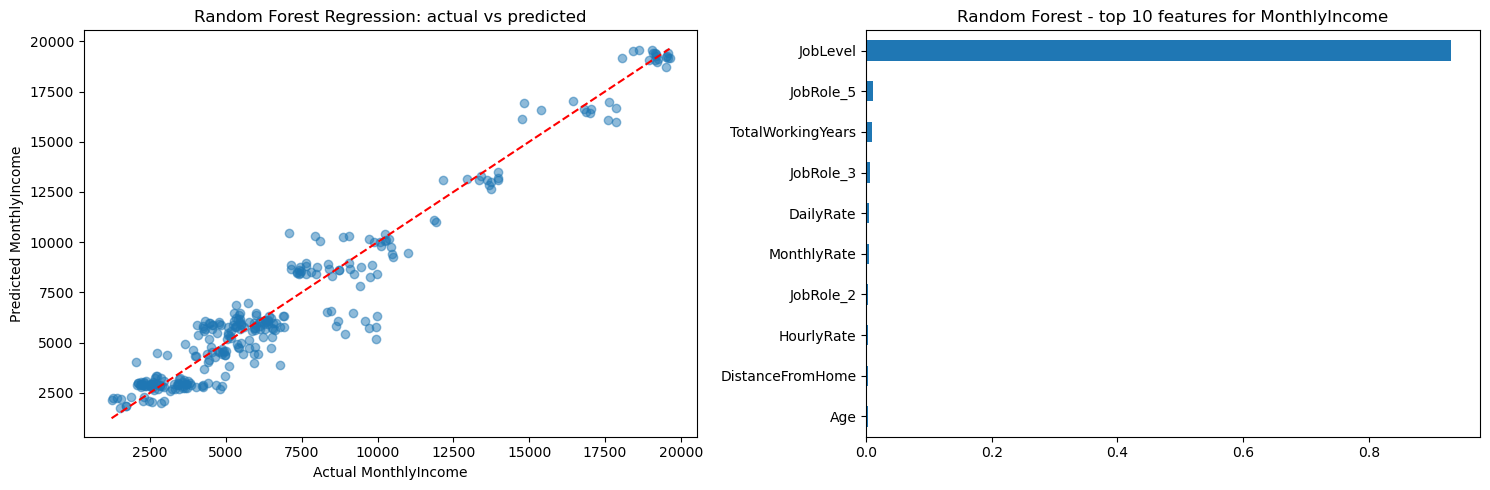

In [ ]:
best_reg_name = regression_df.iloc[0]["Model"]
best_reg = reg_fitted[best_reg_name]
pred_reg = best_reg.predict(Xr_test)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(yr_test, pred_reg, alpha=0.5)
lims = [yr_test.min(), yr_test.max()]
axes[0].plot(lims, lims, "r--")
axes[0].set_xlabel("Actual MonthlyIncome")
axes[0].set_ylabel("Predicted MonthlyIncome")
axes[0].set_title(f"{best_reg_name}: actual vs predicted")

rf_pipe = reg_fitted["Random Forest Regression"]
names = rf_pipe.named_steps["preprocessor"].get_feature_names_out()
imp = pd.Series(rf_pipe.named_steps["regressor"].feature_importances_, index=names)
imp.index = [n.split("__", 1)[1] for n in imp.index]
imp.nlargest(10).sort_values().plot.barh(ax=axes[1])
axes[1].set_title("Random Forest - top 10 features for MonthlyIncome")
plt.tight_layout()
plt.show()

Clustering matrix: (1470, 49)


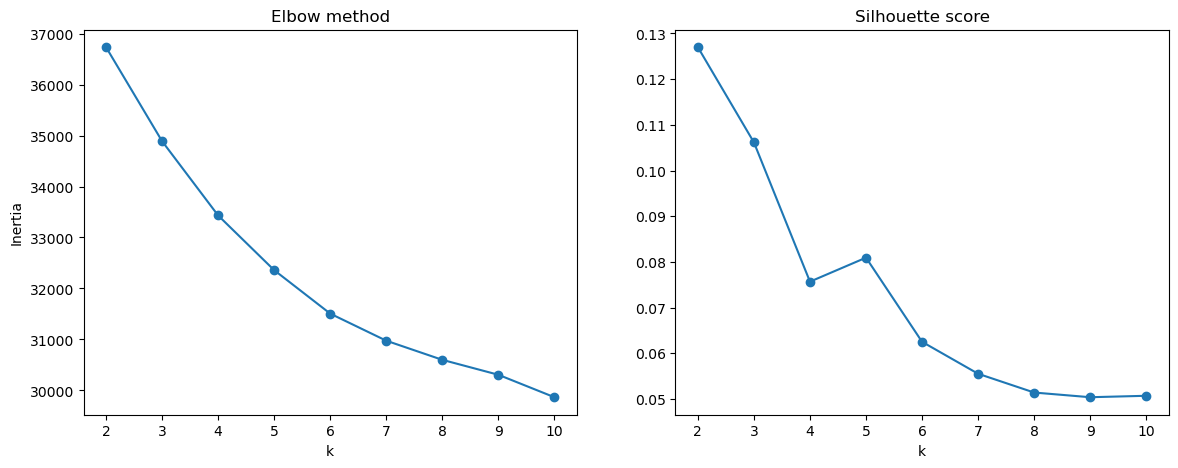

In [ ]:
# Unsupervised learning
X_cluster = clone(preprocessor).fit_transform(X)
print("Clustering matrix:", X_cluster.shape)

k_range = range(2, 11)
inertia, silhouette = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X_cluster)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_cluster, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(list(k_range), inertia, "o-")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("k")
axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_range), silhouette, "o-")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("k")
plt.show()

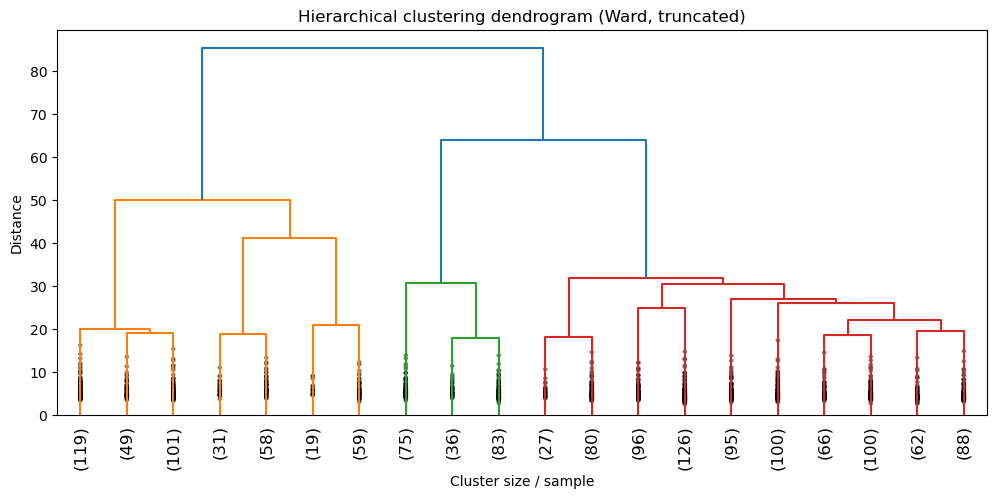

Silhouette  K-Means     : 0.076
Silhouette  Hierarchical: 0.073
Agreement (Adjusted Rand Index) K-Means vs Hierarchical: 0.676


In [ ]:
# Clusters
N_CLUSTERS = 4

kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED).fit(X_cluster)
kmeans_labels = kmeans.labels_

# Hierarchical clustering (Ward linkage)
Z = linkage(X_cluster, method="ward")
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=20, leaf_rotation=90, show_contracted=True)
plt.title("Hierarchical clustering dendrogram (Ward, truncated)")
plt.xlabel("Cluster size / sample")
plt.ylabel("Distance")
plt.show()

hier_labels = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage="ward").fit_predict(X_cluster)

print("Silhouette  K-Means     :", round(silhouette_score(X_cluster, kmeans_labels), 3))
print("Silhouette  Hierarchical:", round(silhouette_score(X_cluster, hier_labels), 3))
print("Agreement (Adjusted Rand Index) K-Means vs Hierarchical:",
      round(adjusted_rand_score(kmeans_labels, hier_labels), 3))

Components needed for 90% variance: 22
Variance explained by PC1 + PC2: 0.233


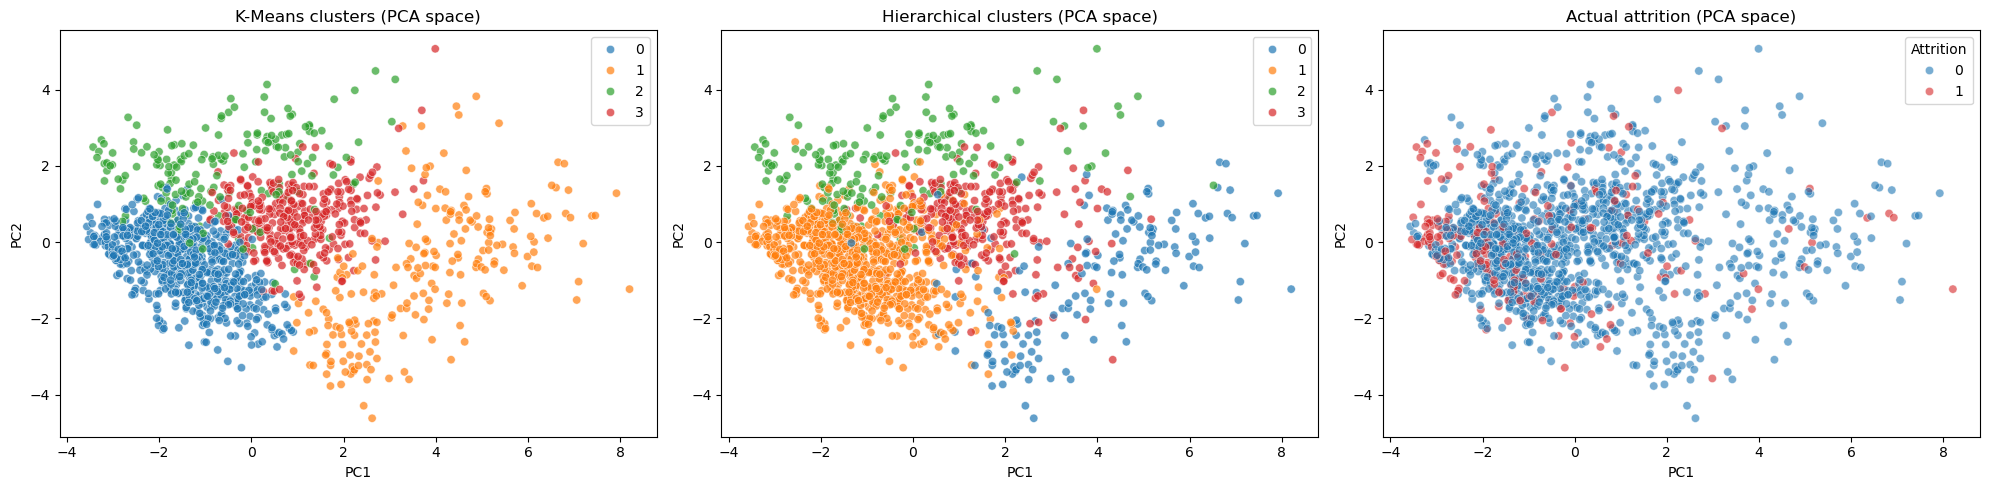

In [ ]:
# PCA -> 2D for visualisation
pca_full = PCA(random_state=SEED).fit(X_cluster)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
print("Components needed for 90% variance:", int(np.argmax(cum_var >= 0.90)) + 1)

pca = PCA(n_components=2, random_state=SEED)
pca_coords = pca.fit_transform(X_cluster)
print("Variance explained by PC1 + PC2:", round(pca.explained_variance_ratio_.sum(), 3))

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
sns.scatterplot(x=pca_coords[:, 0], y=pca_coords[:, 1], hue=kmeans_labels,
                palette="tab10", alpha=0.7, ax=axes[0])
axes[0].set_title("K-Means clusters (PCA space)")
sns.scatterplot(x=pca_coords[:, 0], y=pca_coords[:, 1], hue=hier_labels,
                palette="tab10", alpha=0.7, ax=axes[1])
axes[1].set_title("Hierarchical clusters (PCA space)")
sns.scatterplot(x=pca_coords[:, 0], y=pca_coords[:, 1], hue=employee_df["Attrition"],
                palette={0: "tab:blue", 1: "tab:red"}, alpha=0.6, ax=axes[2])
axes[2].set_title("Actual attrition (PCA space)")
for ax in axes:
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

,Size,Age,MonthlyIncome,JobLevel,YearsAtCompany,TotalWorkingYears,DistanceFromHome,JobSatisfaction,OverTimeShare,AttritionRate
Cluster,,,,,,,,,,
0,714,34.27,4334.05,1.53,3.39,7.20,9.11,2.73,0.30,0.21
1,222,47.99,15383.64,4.06,14.72,25.40,8.58,2.66,0.29,0.08
2,195,35.26,4976.95,1.72,5.73,9.11,9.81,2.73,0.30,0.19
3,339,36.22,6133.11,2.09,10.32,11.88,9.42,2.77,0.24,0.10


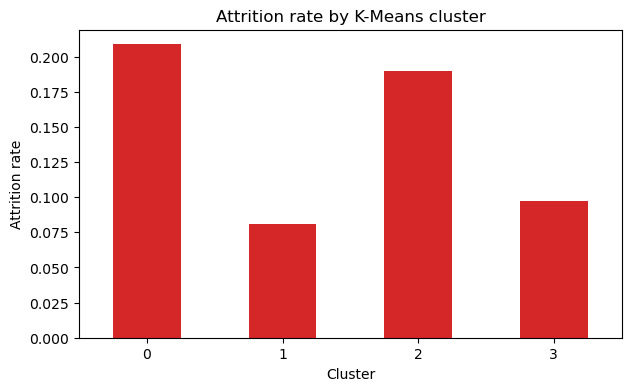

In [ ]:
# Cluster characteristics + attrition within each cluster
profile_cols = ["Age", "MonthlyIncome", "JobLevel", "YearsAtCompany",
                "TotalWorkingYears", "DistanceFromHome", "JobSatisfaction",
                "OverTime", "Attrition"]

cluster_profile = (
    employee_df.assign(Cluster=kmeans_labels)
    .groupby("Cluster")[profile_cols].mean()
    .rename(columns={"Attrition": "AttritionRate", "OverTime": "OverTimeShare"})
)
cluster_profile.insert(0, "Size", pd.Series(kmeans_labels).value_counts().sort_index())
display(cluster_profile.round(2))

cluster_profile["AttritionRate"].plot.bar(figsize=(7, 4), color="tab:red")
plt.title("Attrition rate by K-Means cluster")
plt.ylabel("Attrition rate")
plt.xticks(rotation=0)
plt.show()

,Employees,Actual_Attrition_Rate
Risk_Category,,
Low,935,0.063
Medium,263,0.175
High,272,0.485


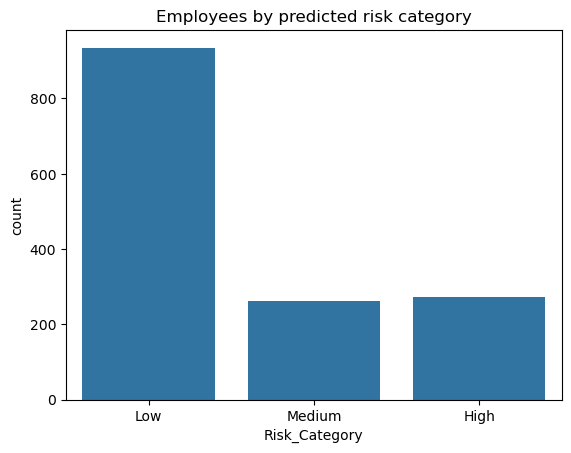

In [ ]:
# Employee risk prediction
oof_proba = cross_val_predict(clone(final_model), X, y, cv=cv,
                              method="predict_proba", n_jobs=-1)[:, 1]

def risk_category(p):
    if p < 0.30:
        return "Low"
    elif p <= 0.60:
        return "Medium"
    return "High"

risk_df = pd.DataFrame({
    "EmployeeID": np.arange(1, len(employee_df) + 1),
    "Predicted_Attrition": (oof_proba >= 0.5).astype(int),
    "Attrition_Probability": oof_proba.round(4),
})
risk_df["Risk_Category"] = risk_df["Attrition_Probability"].apply(risk_category)
risk_df["Risk_Category"] = pd.Categorical(risk_df["Risk_Category"],
                                          ["Low", "Medium", "High"], ordered=True)

# Sanity check: actual attrition should rise from Low -> High
check = (risk_df.assign(Actual=y.values)
         .groupby("Risk_Category", observed=True)
         .agg(Employees=("EmployeeID", "count"), Actual_Attrition_Rate=("Actual", "mean")))
display(check.round(3))

sns.countplot(data=risk_df, x="Risk_Category", order=["Low", "Medium", "High"])
plt.title("Employees by predicted risk category")
plt.show()